In [1]:
# https://github.com/magic-telescopes/acme_magic_odas
# https://docs.gammapy.org/1.3/tutorials/analysis-1d/ebl.html

In [2]:
# - basic imports (numpy, astropy, regions, matplotlib)
import astropy.units as u
from pathlib import Path
from astropy.coordinates import SkyCoord
from regions import PointSkyRegion
import matplotlib.pyplot as plt
import logging
import warnings

# - Gammapy's imports
from gammapy.maps import MapAxis, RegionGeom
from gammapy.data import DataStore
from gammapy.datasets import SpectrumDataset, Datasets
from gammapy.makers import (
    SpectrumDatasetMaker,
    WobbleRegionsFinder,
    ReflectedRegionsBackgroundMaker,
)
from gammapy.modeling.models import (
    PowerLawSpectralModel,
    SkyModel,
    EBL_DATA_BUILTIN,
    EBLAbsorptionNormSpectralModel,
)
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator

# - setting up logging and ignoring warnings
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)
# warnings.filterwarnings("ignore")

/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Load the DL3 data store from the directory containing the FITS index files.
# DataStore.from_dir reads the hdu-index and obs-index FITS tables from the given path,
# which together describe all available observations and their associated IRF files.
datastore = DataStore.from_dir("../../MAGICDATA/B21420+326_dl3_data/standard_trigger")

# Retrieve all observations from the datastore.
# required_irf filters to only include observations that have all three IRF components:
#   rad_max  : the theta^2 cut defining the signal extraction region
#   aeff     : effective collection area as a function of energy and offset
#   edisp    : energy dispersion matrix mapping true to reconstructed energy
observations = datastore.get_observations(required_irf=["rad_max", "aeff", "edisp"])

In [4]:
# Define the parameters of the spectrum extraction.

# Resolve the sky coordinates of OQ 334 by name using the CDS name resolver.
# This returns a SkyCoord object with the RA and Dec of the source.
coords = SkyCoord.from_name("OQ 334")

# Define the on region as a point source region centred on OQ 334.
# The extraction radius is not set manually here — it will be fetched from the RAD_MAX table in the IRFs for each observation.
on_region = PointSkyRegion(coords)

# Define the energy axis for binning the counts (reconstructed/estimated energies).
# This is the energy axis used for the observed counts histogram.
# 1 GeV to 100 TeV, 20 bins, linearly spaced in log (per_decade=False here means nbin=20 is the total number of bins across the full range).
energy_axis = MapAxis.from_energy_bounds(
    1, 1e5, nbin=20, per_decade=False, unit="GeV", name="energy"
)

# Define the energy axis for IRF interpolation (true energies).
# A finer binning (30 bins) is used here to accurately interpolate the effective area and energy dispersion at true photon energies.
energy_axis_true = MapAxis.from_energy_bounds(
    1, 1e5, nbin=30, per_decade=False, unit="GeV", name="energy_true"
)

# Create the spatial geometry of the dataset using the on region and energy axis.
# RegionGeom defines a 1D spectral geometry (no spatial pixels) over the on region.
geom = RegionGeom.create(region=on_region, axes=[energy_axis])

# Create an empty SpectrumDataset with the defined geometry and true energy axis.
# This serves as the template that will be filled with counts and IRFs
# for each observation during the data reduction step.
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

In [5]:
# Create the dataset maker for spectral extraction.
# containment_correction=False is appropriate for point sources observed with MAGIC, where the on region is defined by RAD_MAX
# (already accounts for the PSF); applying an additional containment correction would double-count.
# selection specifies which IRF components to compute:
#   "counts"   — observed photon counts in the on region
#   "exposure" — effective area × livetime (used to compute flux)
#   "edisp"    — energy dispersion matrix (maps true energy to reconstructed energy)
dataset_maker = SpectrumDatasetMaker(
    containment_correction=False, selection=["counts", "exposure", "edisp"]
)

# Use the wobble observation pattern to find off regions.
# In wobble mode the source is offset from the camera centre, so symmetric off regions at the same camera offset 
# (and therefore the same acceptance) can be placed azimuthally around the pointing direction.
# n_off_regions=3 means three such reflected regions are used, increasing the background statistics by a factor of 3.
region_finder = WobbleRegionsFinder(n_off_regions=3)

# Create the background estimator using the reflected regions method.
# For each observation it identifies the off regions found above and fills the background estimate from counts in those regions (Li & Ma formalism).
bkg_maker = ReflectedRegionsBackgroundMaker(region_finder=region_finder)

# Initialise an empty Datasets container to collect the per-observation datasets.
datasets = Datasets()

for observation in observations:
    # Run the dataset maker for this observation using a fresh copy of the empty template. 
    # The copy is named by obs_id so each dataset is uniquely identified in the container.
    dataset = dataset_maker.run(
        dataset_empty.copy(name=str(observation.obs_id)), observation
    )

    # Estimate the background for this observation using the reflected regions
    # and convert the dataset to an on-off format (SpectrumDatasetOnOff),
    # which stores on counts, off counts, and the alpha (exposure ratio) separately.
    dataset_on_off = bkg_maker.run(dataset, observation)

    datasets.append(dataset_on_off)

'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' 

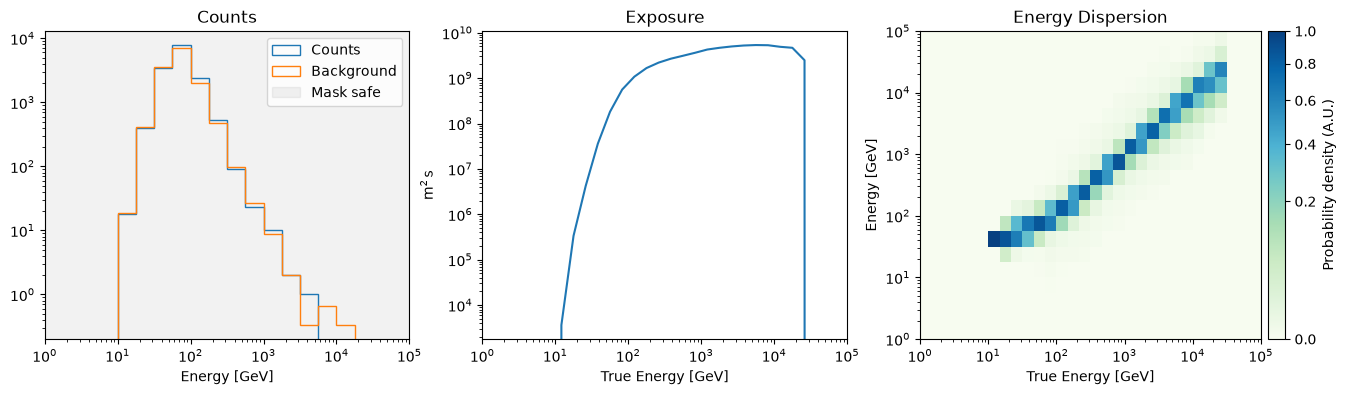

In [6]:
# All the single observation dataset combined into one dataset. Counts, background, IRFs etc are combined into one final dataset. 
stacked = datasets.stack_reduce(name="OQ334MAGIC")

# Display a quick diagnostic overview of the stacked dataset
stacked.peek()

In [7]:
# Declare the energy range to be used for spectral fitting.
e_min = 50 * u.GeV 
e_max = 500 * u.GeV

# Apply the energy range as a boolean fit mask on the stacked dataset.
# Bins outside [e_min, e_max] are masked and excluded from the likelihood during spectral fitting; counts and background in those bins are ignored.
stacked.mask_fit = stacked.counts.geom.energy_mask(e_min, e_max)

In [8]:
# Assume the intrinsic VHE spectrum of OQ 334 is a power law.
# The observed spectrum is then a CompoundSpectralModel: the intrinsic power law attenuated by EBL absorption,
# i.e. F_obs(E) = F_int(E) × exp(-τ(E, z)).

# Define the intrinsic power law spectral model with initial parameter guesses.
pwl_model = PowerLawSpectralModel(
    amplitude=5e-12 * u.Unit("TeV-1 cm-2 s-1"),
    reference=0.1 * u.TeV,
    index=2.0 * u.Unit(""),
)

# Set hard bounds on amplitude to keep the optimizer in a physically valid regime
# and to allow upper limit computation to proceed without hitting a boundary at zero.
pwl_model.amplitude.min = 1e-20
pwl_model.amplitude.max = 1e-5

# Define the EBL absorption model using the Domínguez et al. (2011) EBL template.
# The model integrates the optical depth τ(E, z) along the line of sight to this redshift.
redshift = 0.681
absorption = EBLAbsorptionNormSpectralModel.read_builtin("dominguez", redshift=redshift)

# Construct the observed spectral model as the product of the intrinsic power law and the EBL attenuation.
spectral_model = pwl_model * absorption
print(spectral_model)

CompoundSpectralModel
    Component 1 : PowerLawSpectralModel

type    name     value         unit      ...    max    frozen link prior
---- --------- ---------- -------------- ... --------- ------ ---- -----
         index 2.0000e+00                ...       nan  False           
     amplitude 5.0000e-12 TeV-1 s-1 cm-2 ... 1.000e-05  False           
     reference 1.0000e-01            TeV ...       nan   True           
    Component 2 : EBLAbsorptionNormSpectralModel

type    name      value    unit   error   min max frozen link prior
---- ---------- ---------- ---- --------- --- --- ------ ---- -----
       redshift 6.8100e-01      0.000e+00 nan nan   True           
     alpha_norm 1.0000e+00      0.000e+00 nan nan   True           
    Operator : mul



In [9]:
# Wrap the spectral model into a full SkyModel. 
# SkyModel is Gammapy's top-level source component that combines spectral, spatial, and temporal descriptions of a gamma-ray source.

# SkyModel is a factorised model: spectral(E) * spatial(lon, lat) * temporal(t)
# Here only a spectral component is provided, meaning:
#   - No spatial model → the source is treated as a point source or handled by the dataset geometry
#   - No temporal model → a constant (steady) emission is assumed by default

# Parameters used:
#   spectral_model : a SpectralModel instance (e.g. CompoundSpectralModel) already defined above.
#   name           : a string identifier for this model
model = SkyModel(spectral_model=spectral_model, name="OQ334Model")

# Assign the model (or list of models) to the stacked dataset for fitting.
stacked.models = [model]

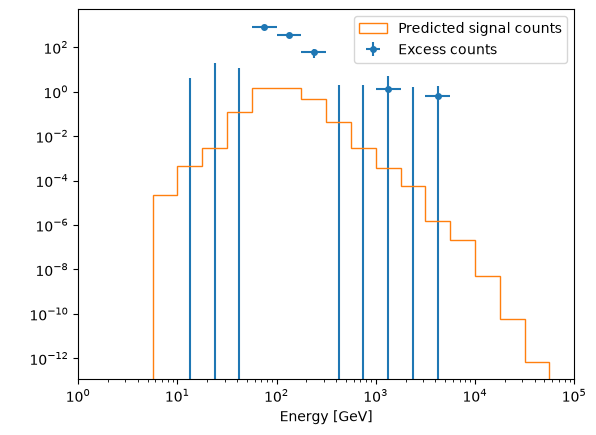

In [10]:
# Plot excess and predicted signal.
stacked.plot_excess()
plt.show()

In [11]:
# Initialise the Fit object with default settings (Minuit optimiser).
fit = Fit()

# Run the fit on the stacked dataset. This optimises the free parameters of the assigned model by minimising the fit statistic.
results = fit.run(datasets=stacked)
print(results)

# Print the updated spectral model with the best-fit parameter values and uncertainties.
print(spectral_model)

# print(results.models.to_parameters_table())

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 135
	total stat : 0.08

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.

CompoundSpectralModel
    Component 1 : PowerLawSpectralModel

type    name     value         unit      ...    max    frozen link prior
---- --------- ---------- -------------- ... --------- ------ ---- -----
         index 3.4758e+00                ...       nan  False           
     amplitude 1.3696e-09 TeV-1 s-1 cm-2 ... 1.000e-05  False           
     reference 1.0000e-01            TeV ...       nan   True           
    Component 2 : EBLAbsorptionNormSpectralModel

type    name      value    unit   error   min max frozen link prior
---- ---------- ---------- ---- --------- --- --- ------ ---- -----
       redshift 6.8100e-01      0.000e+00 nan nan   True           
     alpha_norm 1.0000e+00 

In [12]:
# we make a copy here to compare it later
model_best = model.copy()

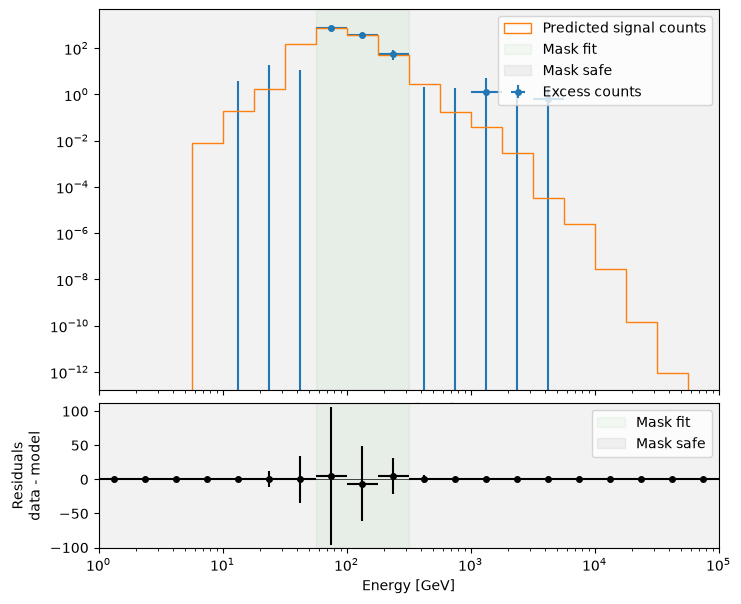

In [13]:
# Plot spectrum and residuals in two panels.
ax_spectrum, ax_residuals = stacked.plot_fit()
plt.show()

In [14]:
# Extract the energy bin edges from the stacked dataset's energy axis.
# [7:11] selects a subset of bins compatible with the energy range used in the likelihood fit.
energy_edges = stacked.counts.geom.axes["energy"].edges[7:11]

# Initialise the FluxPointsEstimator.
# FluxPointsEstimator re-fits only the amplitude (norm) of the best-fit spectrum
# independently in each energy bin, producing one flux measurement per bin.
# Parameters used:
#   energy_edges      : edges defining the energy bins for the flux points
#   source            : name of the SkyModel component to compute flux points for
#   selection_optional : "all" computes asymmetric errors, upper limits, and stat profiles
fpe_magic = FluxPointsEstimator(
    energy_edges=energy_edges, 
    source="OQ334Model", 
    selection_optional="all"
)

# Run the flux point estimation on the stacked dataset.
# Returns a FluxPoints object containing the flux, errors, and upper limits per energy bin.
flux_points_obs = fpe_magic.run(datasets=stacked)

In [15]:
# To get the deabsorbed flux points (i.e. intrinsic points), we simply need to
# set the reference model to the best fit power law instead of the compound model.
# The compound model includes EBL absorption, so replacing it with the pure power law
# removes the absorption component and recovers the intrinsic source flux.
flux_points_intrinsic = flux_points_obs.copy(
    reference_model=SkyModel(spectral_model=pwl_model)
)

# Print the reference model of the observed flux points.
# This should be the compound model (power law * EBL absorption).
print(flux_points_obs.reference_model)

# Print the reference model of the intrinsic flux points.
# This should be the power law with no absorption applied.
print(flux_points_intrinsic.reference_model)

Changing the reference model will change the fluxes. Handle with care.


SkyModel

  Name                      : -urSw1yX
  Datasets names            : None
  Spectral model type       : CompoundSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      3.476   +/-    0.32             
    amplitude                     :   1.37e-09   +/- 1.8e-10 1 / (TeV s cm2)
    reference             (frozen):      0.100       TeV         
    redshift              (frozen):      0.681                   
    alpha_norm            (frozen):      1.000                   


SkyModel

  Name                      : rhzxbh3P
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      3.476   +/-    0.32             
    amplitude                     :   1.37e-09   +/- 1.8e-10 1 / (TeV s cm2)
    reference             (frozen):      0.100       TeV         




/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(
/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


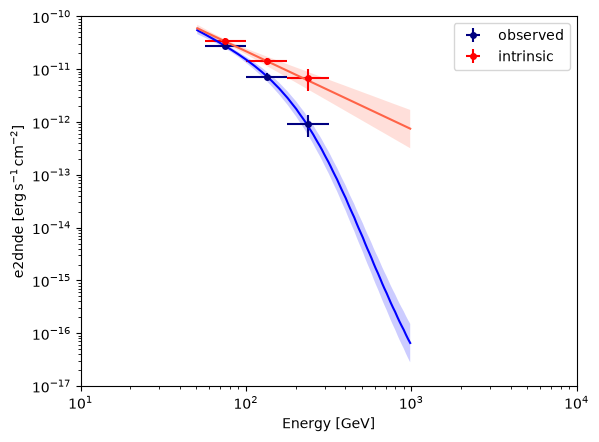

In [16]:
plt.figure()
sed_type = "e2dnde"
energy_bounds = [50, 1e3] * u.GeV

ax = flux_points_obs.plot(sed_type=sed_type, label="observed", color="navy")
flux_points_intrinsic.plot(ax=ax, sed_type=sed_type, label="intrinsic", color="red")

# Plot the best-fit compound spectral model (power law * EBL absorption).
model_best.spectral_model.plot(
    ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="blue"
)

# Plot the 1-sigma uncertainty band of the absorbed best-fit model.
model_best.spectral_model.plot_error(
    ax=ax, energy_bounds=energy_bounds, sed_type="e2dnde", facecolor="blue"
)

# Plot the intrinsic best-fit power law model (no EBL absorption).
pwl_model.plot(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="tomato")

# Plot the 1-sigma uncertainty band of the intrinsic power law model.
pwl_model.plot_error(
    ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, facecolor="tomato"
)

ax.set_xlim(10, 1e4)
ax.set_ylim(1e-17, 1e-10)
plt.legend()
plt.show()

In [17]:
# Convert the observed flux points to an Astropy table in E^2 dN/dE format.
table_obs = flux_points_obs.to_table(sed_type="e2dnde", formatted=True)
table_obs.write("MAGIC_sed_flux_points_obs.fits", overwrite=True)
# display(table_obs)

table_intrinsic = flux_points_intrinsic.to_table(sed_type="e2dnde", formatted=True)
table_intrinsic.write("MAGIC_sed_flux_points_intrinsic.fits", overwrite=True)
display(table_intrinsic)

e_ref,e_min,e_max,e2dnde,e2dnde_err,e2dnde_errp,e2dnde_errn,e2dnde_ul,e2dnde_sensitivity,ts,sqrt_ts,npred,npred_excess,stat,stat_null,stat_scan,is_ul,counts,success,norm_scan
GeV,GeV,GeV,erg / (s cm2),erg / (s cm2),erg / (s cm2),erg / (s cm2),erg / (s cm2),erg / (s cm2),,,,,,,,,,,
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64[1],float32[1],float64,float64,float64[11],bool,float64[1],bool,float64[11]
74.989,56.234,100.000,3.384e-11,4.407e-12,4.418e-12,4.397e-12,4.270e-11,1.802e-11,61.058,7.814,7839.99773224102,775.3295,0.000,61.058,38.975 .. 804.288,False,7840.0,True,0.200 .. 5.000
133.352,100.000,177.828,1.404e-11,2.114e-12,2.123e-12,2.105e-12,1.830e-11,9.107e-12,46.661,6.831,2389.988929782217,367.65204,0.000,46.661,29.200 .. 595.138,False,2390.0,True,0.200 .. 5.000
237.137,177.828,316.228,6.872e-12,3.090e-12,3.118e-12,3.064e-12,1.317e-11,1.797e-11,5.148,2.269,535.9694560899231,58.62704,0.000,5.148,3.450 .. 51.850,False,536.0,True,0.200 .. 5.000


In [18]:
# results_dir = Path("results_dir")
# results_dir.mkdir(exist_ok=True, parents=True)

# # Save the stacked dataset to a YAML file in the results directory.
# # Datasets([stacked]) wraps the single stacked dataset into a Datasets container,
# Datasets([stacked]).write(results_dir / "OQ334_Stacked.yaml", overwrite=True)

/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(
/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


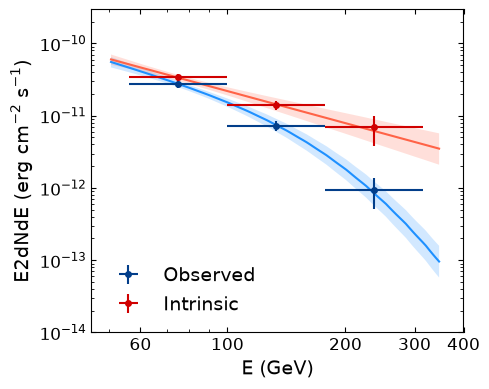

In [19]:
import matplotlib.ticker as mticker

plt.figure(figsize=(5, 4))
sed_type = "e2dnde"
energy_bounds = [50, 350] * u.GeV

ax = flux_points_obs.plot(sed_type=sed_type, label="Observed", color="#023e8a", zorder=3)
flux_points_intrinsic.plot(ax=ax, sed_type=sed_type, label="Intrinsic", color="#d00000", zorder=3)

model_best.spectral_model.plot(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="dodgerblue")
model_best.spectral_model.plot_error(ax=ax, energy_bounds=energy_bounds, sed_type="e2dnde", facecolor="dodgerblue")

pwl_model.plot(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="tomato")
pwl_model.plot_error(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, facecolor="tomato")

ax.set_xlabel(r'E (GeV)', fontsize=14)
ax.set_ylabel(r'E2dNdE (erg cm$^{-2}$ s$^{-1}$)', fontsize=14)
ax.set_xlim(45, 400)
ax.set_ylim(1e-14, 3e-10)

ax.tick_params(axis="both", which="major", labelsize=12, direction="in", top=True, right=True,)
ax.minorticks_on()
ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True,)

ax.set_xticks([60, 100, 200, 300, 400])
ax.xaxis.set_major_formatter(mticker.ScalarFormatter())

plt.legend(fontsize=14, loc="lower left", frameon=False,)
plt.tight_layout()
# plt.savefig(f"MAGIC_VHE_SED.pdf", dpi=300)
plt.savefig(f"MAGIC_VHE_SED.png", dpi=300)
plt.show()